# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [2]:
df = pd.read_csv("data/AviationData_Cleaned.csv")

print(df.shape)
display(df.head())

(54454, 30)


,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Airport.Code,Airport.Name,Injury.Severity,Aircraft.damage,...,Total.Minor.Injuries,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,Report.Status,Publication.Date,Total.Persons,Injury.Rate,Aircraft.Destroyed,Aircraft.Type
0,20001214X42095,Accident,SEA83LA036,1983-01-01,"NEWPORT, OR",United States,ONP,NEWPORT MUNICIPAL,Non-Fatal,Substantial,...,1.0,3.0,VMC,Approach,Probable Cause,NaN,4.0,0.0,0.0,CESSNA 182P
1,20001214X42067,Accident,MKC83LA056,1983-01-01,"WOODBINE, IA",United States,3YR,MUNICIPAL,Non-Fatal,Substantial,...,0.0,2.0,VMC,Landing,Probable Cause,NaN,2.0,0.0,0.0,CESSNA 182RG
2,20001214X42063,Accident,MKC83LA050,1983-01-01,"MARYVILLE, MO",United States,78Y,RANKIN,Non-Fatal,Substantial,...,0.0,1.0,VMC,Takeoff,Probable Cause,NaN,1.0,0.0,0.0,CESSNA 182P
3,20001214X42018,Accident,LAX83FUG11,1983-01-01,"UPLAND, CA",United States,CCB,CABLE,Non-Fatal,Substantial,...,2.0,0.0,VMC,Approach,Probable Cause,NaN,2.0,0.0,0.0,PIPER PA-28R-200
4,20001214X41951,Accident,CHI83LA074,1983-01-01,"SPRINGBROOK, WI",United States,NaN,SPRINGBROOK,Non-Fatal,Substantial,...,0.0,2.0,VMC,Landing,Probable Cause,NaN,2.0,0.0,0.0,CESSNA 140


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [3]:
# Separate small and large aircraft
small_planes = df[df["Total.Persons"] < 20].copy()
large_planes = df[df["Total.Persons"] >= 20].copy()

# Check the number of observations
print("Small planes:", small_planes.shape)
print("Large planes:", large_planes.shape)

Small planes: (53610, 30)
Large planes: (844, 30)


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

SMALL PLANES


,mean,count
Make,,
GRUMMAN-SCHWEIZER,0.110644,119
WACO,0.132302,97
GREAT LAKES,0.141509,53
SCHWEIZER,0.150000,120
MAULE,0.157529,487
AVIAT AIRCRAFT INC,0.164474,76
GRUMMAN,0.179748,921
HELIO,0.182821,68
MCDONNELL DOUGLAS,0.193277,34


LARGE PLANES


,mean,count
Make,,
AERO COMMANDER,0.000000,1
DEHAVILLAND,0.000000,1
SWEARINGEN,0.000000,2
CESSNA,0.006792,6
MCDONNELL DOUGLAS,0.027718,112
EMBRAER,0.089580,58
BOEING,0.110194,533
LEARJET,0.130435,1
AIRBUS,0.139788,70


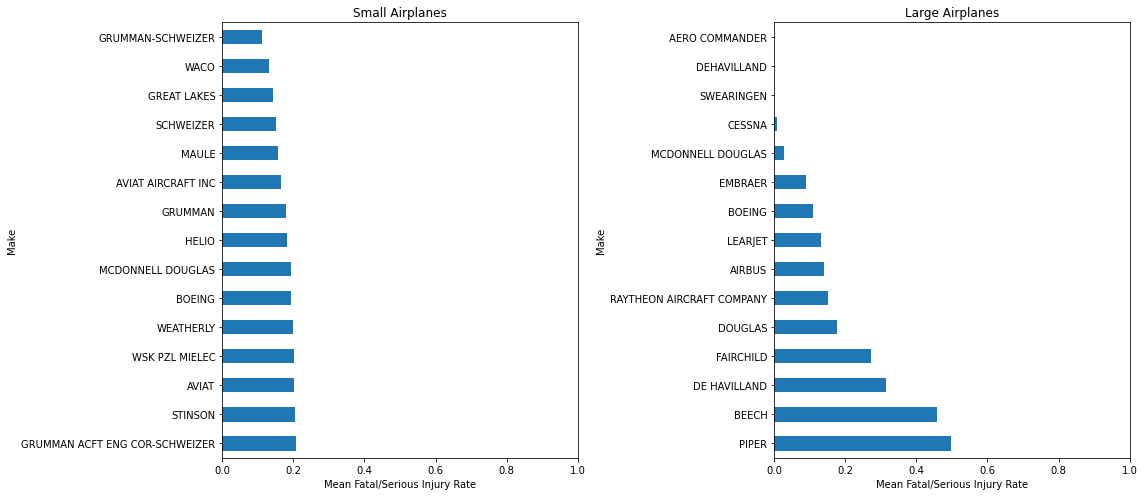

In [4]:
# Mean injury rates by manufacturer
small_make_rates = (
    small_planes.groupby("Make")["Injury.Rate"]
    .agg(["mean", "count"])
    .sort_values("mean")
)

large_make_rates = (
    large_planes.groupby("Make")["Injury.Rate"]
    .agg(["mean", "count"])
    .sort_values("mean")
)

print("SMALL PLANES")
display(small_make_rates.head(15))

print("LARGE PLANES")
display(large_make_rates.head(15))


fig, axes = plt.subplots(1, 2, figsize=(16, 7))

small_make_rates.head(15)["mean"].plot(
    kind="barh", ax=axes[0], title="Small Airplanes"
)

large_make_rates.head(15)["mean"].plot(
    kind="barh", ax=axes[1], title="Large Airplanes"
)

for ax in axes:
    ax.set_xlabel("Mean Fatal/Serious Injury Rate")
    ax.set_ylabel("Make")
    ax.invert_yaxis()
    ax.set_xlim(0, 1)

plt.tight_layout()
plt.show()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

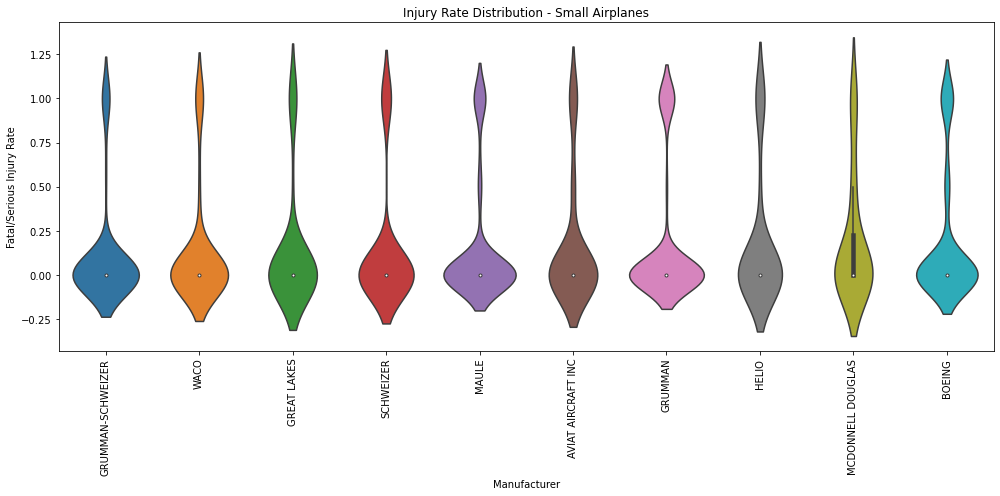

In [5]:
# Select the 10 makes with the lowest mean injury rates
top10_small = small_make_rates.head(10).index

# Filter the dataset
small_top10 = small_planes[
    small_planes["Make"].isin(top10_small)
]

# Create violinplot
plt.figure(figsize=(14, 7))

sns.violinplot(
    data=small_top10,
    x="Make",
    y="Injury.Rate",
    order=top10_small
)

plt.xticks(rotation=90)
plt.title("Injury Rate Distribution - Small Airplanes")
plt.xlabel("Manufacturer")
plt.ylabel("Fatal/Serious Injury Rate")

plt.tight_layout()
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

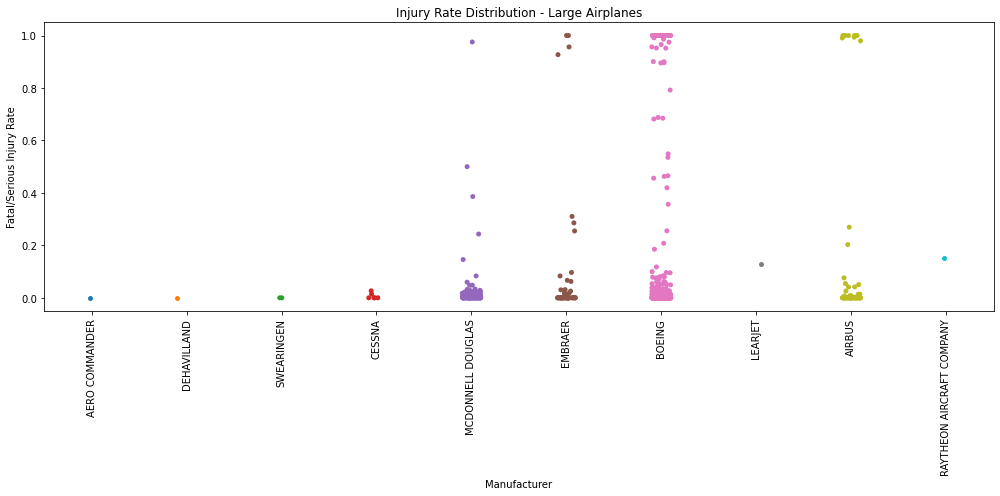

In [6]:
# Select the 10 makes with the lowest mean injury rates
top10_large = large_make_rates.head(10).index

# Filter the dataset
large_top10 = large_planes[
    large_planes["Make"].isin(top10_large)
]

# Create stripplot
plt.figure(figsize=(14, 7))

sns.stripplot(
    data=large_top10,
    x="Make",
    y="Injury.Rate",
    order=top10_large,
    jitter=True
)

plt.xticks(rotation=90)
plt.title("Injury Rate Distribution - Large Airplanes")
plt.xlabel("Manufacturer")
plt.ylabel("Fatal/Serious Injury Rate")

plt.tight_layout()
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

In [7]:
# Calculate aircraft destruction rates by Make
small_destruction = (
    small_planes.groupby("Make")["Aircraft.Destroyed"]
    .agg(["mean", "count"])
    .sort_values("mean")
    .head(15)
)

large_destruction = (
    large_planes.groupby("Make")["Aircraft.Destroyed"]
    .agg(["mean", "count"])
    .sort_values("mean")
    .head(15)
)

print("SMALL PLANES - DESTRUCTION RATE")
display(small_destruction)

print("LARGE PLANES - DESTRUCTION RATE")
display(large_destruction)

SMALL PLANES - DESTRUCTION RATE


,mean,count
Make,,
GRUMMAN ACFT ENG COR-SCHWEIZER,0.017241,58
AMERICAN CHAMPION AIRCRAFT,0.037736,53
AVIAT AIRCRAFT INC,0.040000,75
DEHAVILLAND,0.043011,93
DIAMOND AIRCRAFT IND INC,0.055556,72
AVIAT,0.075188,133
MAULE,0.088296,487
ERCOUPE,0.097222,72
LUSCOMBE,0.099448,362


LARGE PLANES - DESTRUCTION RATE


,mean,count
Make,,
AERO COMMANDER,0.000000,1
DEHAVILLAND,0.000000,1
RAYTHEON AIRCRAFT COMPANY,0.000000,1
SWEARINGEN,0.000000,2
MCDONNELL DOUGLAS,0.102564,78
EMBRAER,0.121212,33
CESSNA,0.166667,6
BOEING,0.216606,277
AIRBUS,0.243243,37


#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

For small airplanes, GRUMMAN-SCHWEIZER and WACO show low injury rates, while GRUMMAN ACFT ENG COR-SCHWEIZER and AMERICAN CHAMPION AIRCRAFT have the lowest destruction rates.

For large airplanes, MCDONNELL DOUGLAS performs well on both metrics, with a 2.77% injury rate and a 10.26% destruction rate.

However, small sample sizes limit reliability. These results measure accident severity, not accident probability. Flight frequency and aircraft usage data are needed for stronger safety recommendations.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

,mean,count
Aircraft.Type,,
BOEING 717-200,0.002024,10
BOEING 757-232,0.005404,16
BOEING 757-222,0.007383,11
MCDONNELL DOUGLAS MD-88,0.007457,12
MCDONNELL DOUGLAS DC-10-30,0.011737,10
EMBRAER EMB-145LR,0.016209,12
MCDONNELL DOUGLAS MD-11,0.025407,13
BOEING 747-400,0.057839,12
BOEING 777,0.061818,16


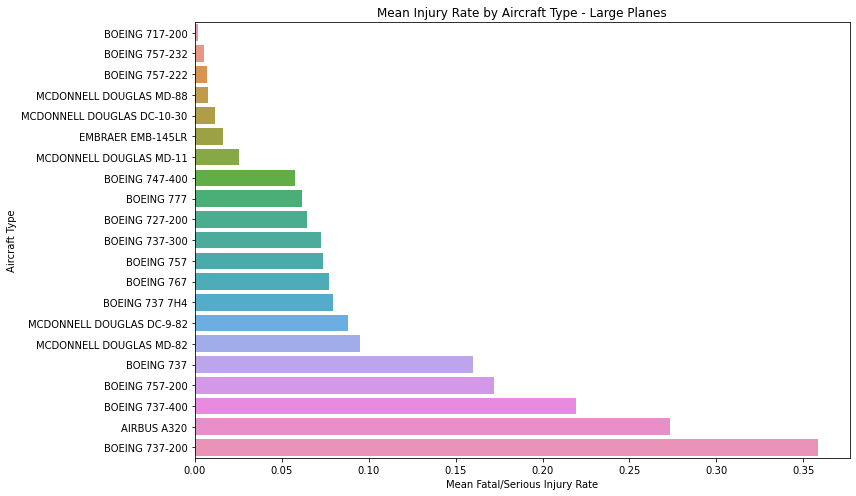

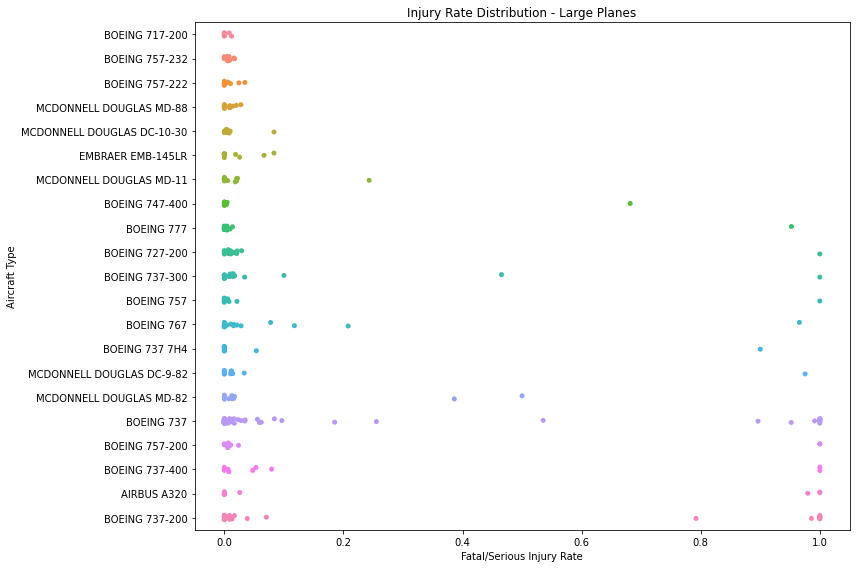

In [8]:
# Calculate injury rates by aircraft type
large_type_rates = (
    large_planes.groupby("Aircraft.Type")["Injury.Rate"]
    .agg(["mean", "count"])
)

# Keep types with at least 10 observations
large_type_rates = large_type_rates[
    large_type_rates["count"] >= 10
].sort_values("mean")

display(large_type_rates)


# Plot mean injury rates
plt.figure(figsize=(12, 7))

sns.barplot(
    x=large_type_rates["mean"],
    y=large_type_rates.index
)

plt.title("Mean Injury Rate by Aircraft Type - Large Planes")
plt.xlabel("Mean Fatal/Serious Injury Rate")
plt.ylabel("Aircraft Type")

plt.tight_layout()
plt.show()

# Select aircraft types with at least 10 observations
selected_types = large_type_rates.index

large_types_filtered = large_planes[
    large_planes["Aircraft.Type"].isin(selected_types)
]

# Plot injury rate distribution
plt.figure(figsize=(12, 8))

sns.stripplot(
    data=large_types_filtered,
    x="Injury.Rate",
    y="Aircraft.Type",
    order=selected_types,
    jitter=True
)

plt.title("Injury Rate Distribution - Large Planes")
plt.xlabel("Fatal/Serious Injury Rate")
plt.ylabel("Aircraft Type")

plt.tight_layout()
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

,mean,count
Aircraft.Type,,
GRUMMAN G164B,0.000000,16
MAULE MX-7-235,0.029412,17
GRUMMAN AA1B,0.050000,10
MAULE M-7-235B,0.050000,10
GRUMMAN-SCHWEIZER G-164A,0.053333,50
MAULE M-4,0.055556,18
BOEING E75,0.075758,33
MAULE M-4-220C,0.108108,37
GRUMMAN G-164,0.116071,84


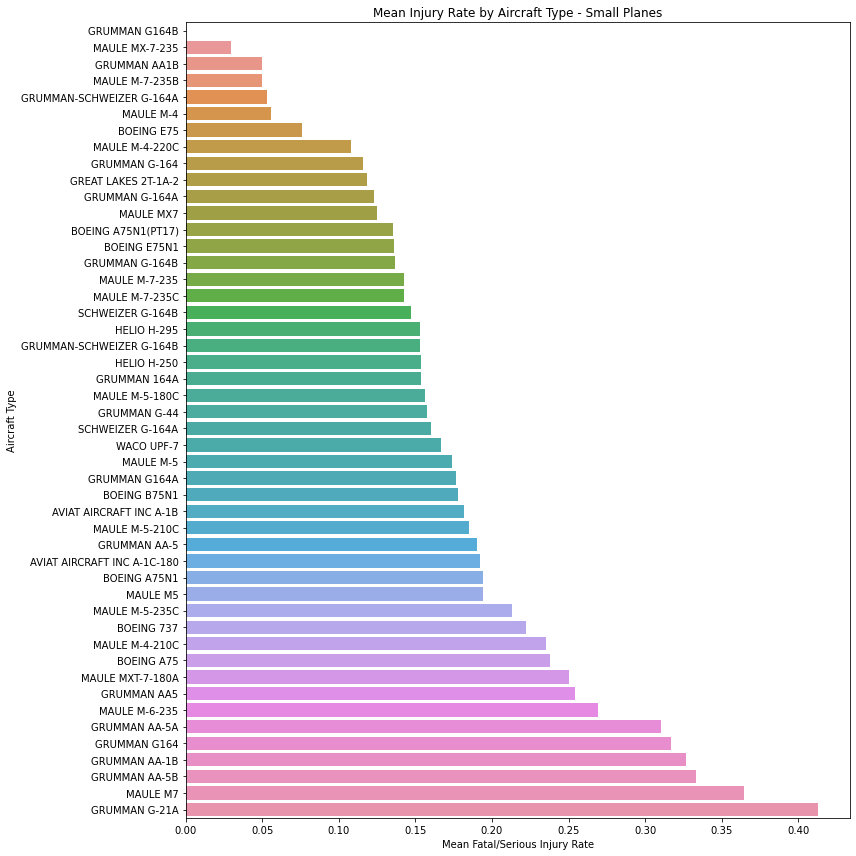

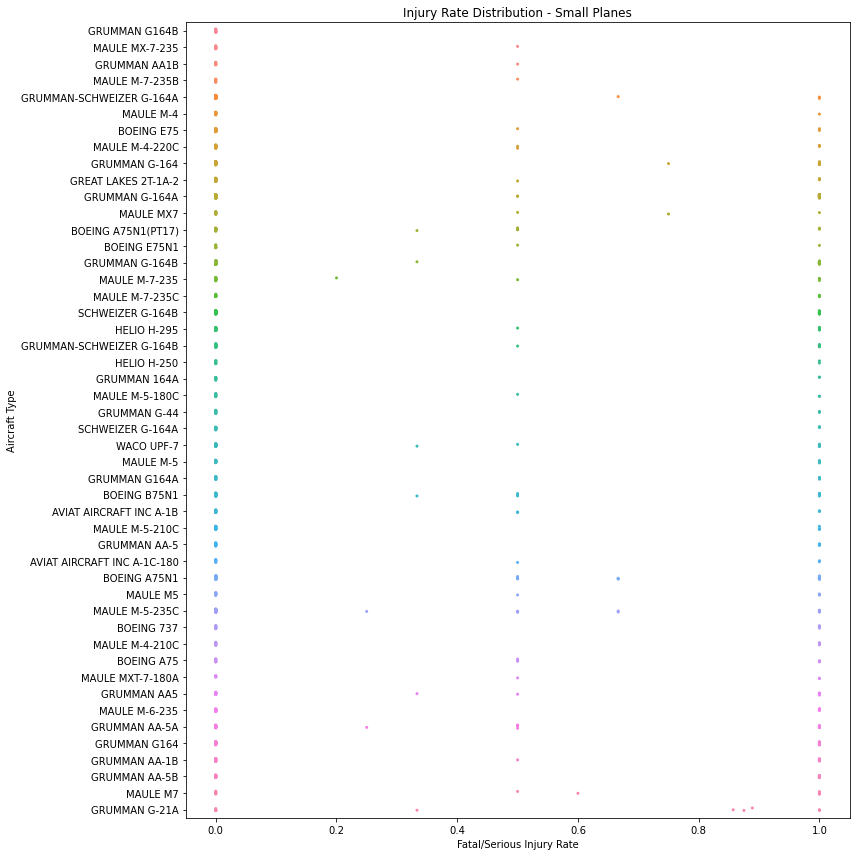

In [9]:
# Select the 10 makes with lowest injury rates
top10_small_makes = small_make_rates.head(10).index

# Filter small airplanes
small_selected = small_planes[
    small_planes["Make"].isin(top10_small_makes)
]

# Calculate injury rates by aircraft type
small_type_rates = (
    small_selected.groupby("Aircraft.Type")["Injury.Rate"]
    .agg(["mean", "count"])
)

# Keep aircraft types with at least 10 observations
small_type_rates = small_type_rates[
    small_type_rates["count"] >= 10
].sort_values("mean")

display(small_type_rates)

# Mean injury rates by aircraft type
plt.figure(figsize=(12, 12))

sns.barplot(
    x=small_type_rates["mean"],
    y=small_type_rates.index
)

plt.title("Mean Injury Rate by Aircraft Type - Small Planes")
plt.xlabel("Mean Fatal/Serious Injury Rate")
plt.ylabel("Aircraft Type")

plt.tight_layout()
plt.show()


# Injury rate distribution
small_types_filtered = small_selected[
    small_selected["Aircraft.Type"].isin(small_type_rates.index)
]

plt.figure(figsize=(12, 12))

sns.stripplot(
    data=small_types_filtered,
    x="Injury.Rate",
    y="Aircraft.Type",
    order=small_type_rates.index,
    jitter=True,
    size=3
)

plt.title("Injury Rate Distribution - Small Planes")
plt.xlabel("Fatal/Serious Injury Rate")
plt.ylabel("Aircraft Type")

plt.tight_layout()
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

Among large airplanes, BOEING 717-200 (0.20%) and BOEING 757-232 (0.54%) show the lowest mean injury rates. For small airplanes, the GRUMMAN G164B (0%) and MAULE MX-7-235 (2.94%) perform best.

However, sample sizes are limited, and inconsistent model names may affect comparisons. The plots show variations in accident severity, not overall accident risk.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

,Mean_Injury_Rate,Destruction_Rate,Accident_Count
Weather.Condition,,,
VMC,0.223044,0.165009,47745
Unknown,0.660156,0.630397,624
IMC,0.680088,0.597179,4252


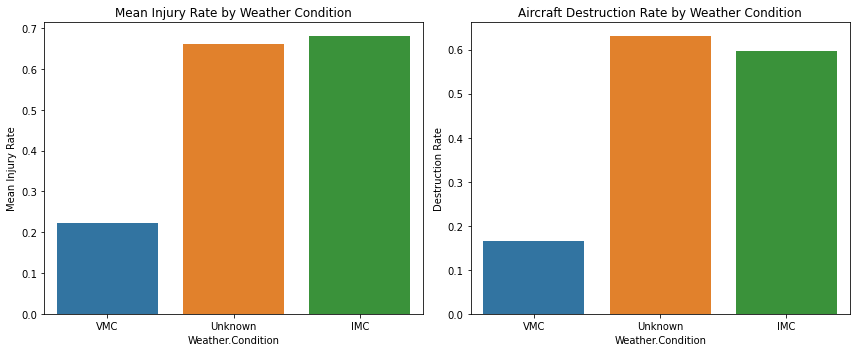

,Mean_Injury_Rate,Destruction_Rate,Accident_Count
Broad.phase.of.flight,,,
Taxi,0.019557,0.020458,1250
Landing,0.035302,0.042296,10737
Standing,0.155533,0.130221,500
Takeoff,0.227623,0.216551,7921
Go-around,0.299300,0.285846,1082
Descent,0.339315,0.335420,1162
Approach,0.352442,0.298467,4056
Cruise,0.353397,0.344935,6464
Other,0.412311,0.340426,48


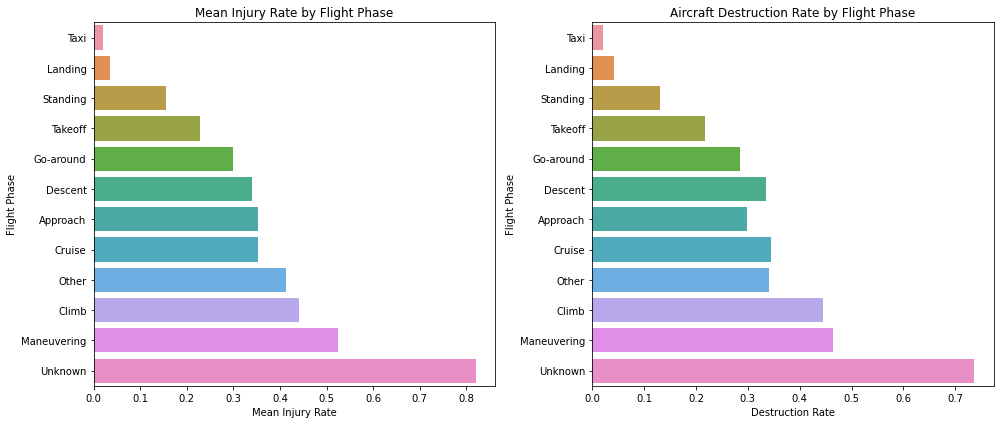

In [10]:
weather_analysis = (
    df.groupby("Weather.Condition")
    .agg(
        Mean_Injury_Rate=("Injury.Rate", "mean"),
        Destruction_Rate=("Aircraft.Destroyed", "mean"),
        Accident_Count=("Event.Id", "count")
    )
    .sort_values("Mean_Injury_Rate")
)

display(weather_analysis)


fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(
    data=weather_analysis.reset_index(),
    x="Weather.Condition",
    y="Mean_Injury_Rate",
    ax=axes[0]
)

axes[0].set_title("Mean Injury Rate by Weather Condition")
axes[0].set_ylabel("Mean Injury Rate")

sns.barplot(
    data=weather_analysis.reset_index(),
    x="Weather.Condition",
    y="Destruction_Rate",
    ax=axes[1]
)

axes[1].set_title("Aircraft Destruction Rate by Weather Condition")
axes[1].set_ylabel("Destruction Rate")

plt.tight_layout()
plt.show()

flight_phase_analysis = (
    df.groupby("Broad.phase.of.flight")
    .agg(
        Mean_Injury_Rate=("Injury.Rate", "mean"),
        Destruction_Rate=("Aircraft.Destroyed", "mean"),
        Accident_Count=("Event.Id", "count")
    )
    .sort_values("Mean_Injury_Rate")
)

display(flight_phase_analysis)


fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.barplot(
    data=flight_phase_analysis.reset_index(),
    x="Mean_Injury_Rate",
    y="Broad.phase.of.flight",
    ax=axes[0]
)

axes[0].set_title("Mean Injury Rate by Flight Phase")
axes[0].set_xlabel("Mean Injury Rate")
axes[0].set_ylabel("Flight Phase")

sns.barplot(
    data=flight_phase_analysis.reset_index(),
    x="Destruction_Rate",
    y="Broad.phase.of.flight",
    ax=axes[1]
)

axes[1].set_title("Aircraft Destruction Rate by Flight Phase")
axes[1].set_xlabel("Destruction Rate")
axes[1].set_ylabel("Flight Phase")

plt.tight_layout()
plt.show()

### Weather Conditions and Flight Phases - conclusion

Accidents under IMC conditions show higher injury rates (68.00%) and aircraft destruction rates (59.72%) than those under VMC conditions (22.30% and 18.50%).

Regarding flight phases, maneuvering has the highest injury rate (52.43%) among identified phases, while taxiing and landing have the lowest.

**Conclusion:** Weather conditions and flight phases are associated with accident severity. However, these findings do not establish causation or overall accident probability.